# Experiment 1: Exploratory Statistical Analysis
**Aim:** To perform exploratory statistical analysis of the Pima Indians Diabetes Dataset by examining its structure, variable types, data quality, statistical characteristics and important patterns.

In [1]:
import warnings
warnings.filterwarnings("ignore")
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline
plt.rcParams["figure.dpi"] = 100
sns.set_style("whitegrid")
COLS = ["Pregnancies","Glucose","BloodPressure","SkinThickness",
        "Insulin","BMI","DiabetesPedigreeFunction","Age","Outcome"]
df = pd.read_csv("pima-indians-diabetes.csv", names=COLS)
print("Dataset shape:", df.shape)
df.head()

Dataset shape: (768, 9)


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72,35,0,33.6,0.627,50,1
1,1,85,66,29,0,26.6,0.351,31,0
2,8,183,64,0,0,23.3,0.672,32,1
3,1,89,66,23,94,28.1,0.167,21,0
4,0,137,40,35,168,43.1,2.288,33,1


In [2]:
# Structure: dimensions, dtypes, statistical summary
print("Data types:"); print(df.dtypes)
print("\nStatistical summary:")
df.describe().round(2)

Data types:
Pregnancies                   int64
Glucose                       int64
BloodPressure                 int64
SkinThickness                 int64
Insulin                       int64
BMI                         float64
DiabetesPedigreeFunction    float64
Age                           int64
Outcome                       int64
dtype: object

Statistical summary:


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
count,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00,768.00
mean,3.85,120.89,69.11,20.54,79.80,31.99,0.47,33.24,0.35
std,3.37,31.97,19.36,15.95,115.24,7.88,0.33,11.76,0.48
min,0.00,0.00,0.00,0.00,0.00,0.00,0.08,21.00,0.00
25%,1.00,99.00,62.00,0.00,0.00,27.30,0.24,24.00,0.00
50%,3.00,117.00,72.00,23.00,30.50,32.00,0.37,29.00,0.00
75%,6.00,140.25,80.00,32.00,127.25,36.60,0.63,41.00,1.00
max,17.00,199.00,122.00,99.00,846.00,67.10,2.42,81.00,1.00


In [3]:
# Data quality: zeros in medical attributes are invalid/missing
zero_cols = ["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]
print("Count of zero (invalid) values per attribute:")
print((df[zero_cols] == 0).sum())

Count of zero (invalid) values per attribute:
Glucose            5
BloodPressure     35
SkinThickness    227
Insulin          374
BMI               11
dtype: int64


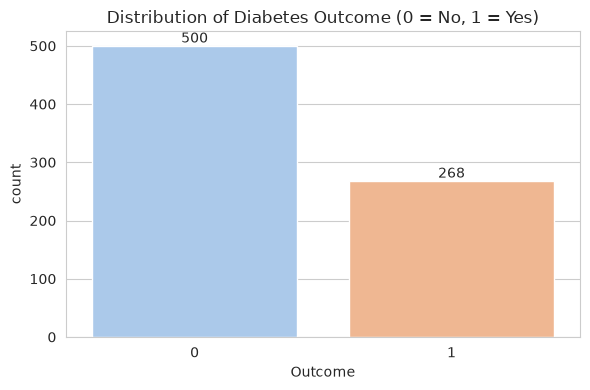

In [4]:
# Outcome distribution
plt.figure(figsize=(6,4))
ax = sns.countplot(x="Outcome", data=df, palette="pastel")
for c in ax.containers: ax.bar_label(c)
plt.title("Distribution of Diabetes Outcome (0 = No, 1 = Yes)")
plt.tight_layout(); plt.savefig("images/fig1_outcome_dist.png", dpi=130, bbox_inches="tight"); plt.show()

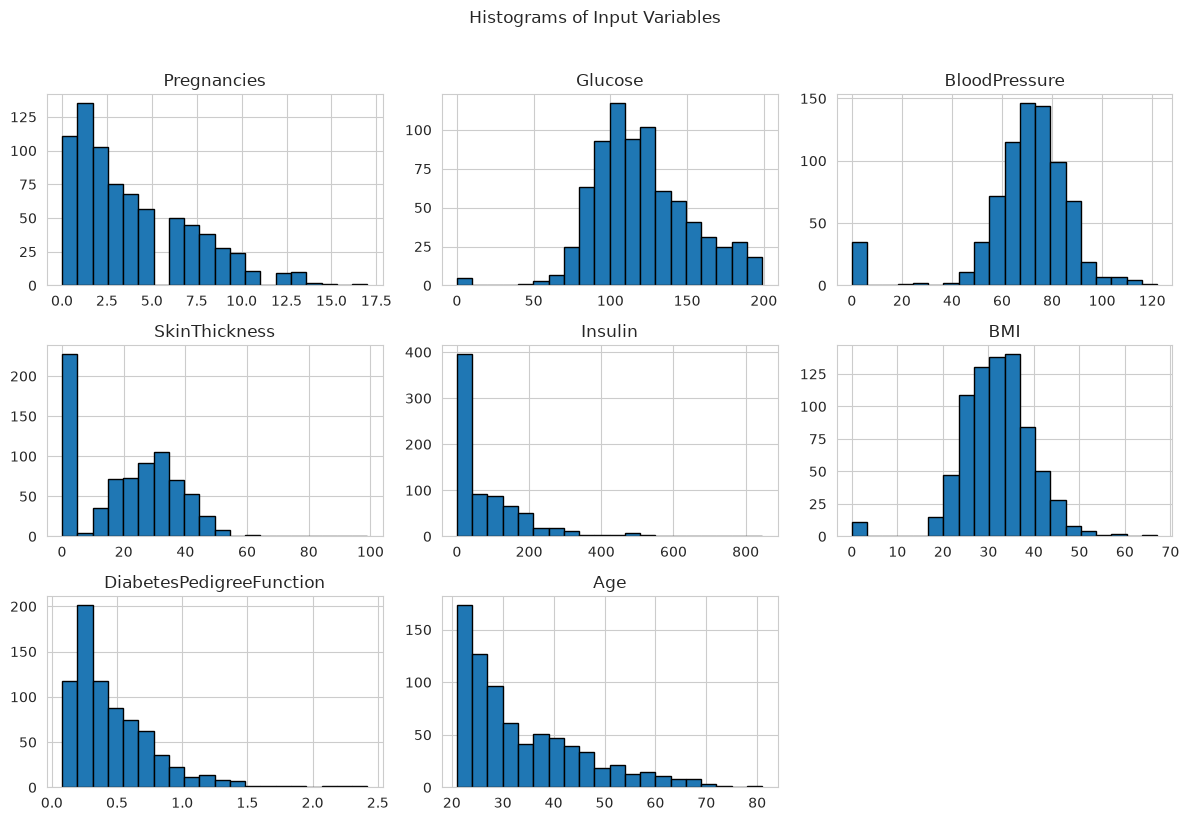

In [5]:
# Histograms of all input variables
df[COLS[:-1]].hist(figsize=(12,8), bins=20, edgecolor="black")
plt.suptitle("Histograms of Input Variables", y=1.02)
plt.tight_layout(); plt.savefig("images/fig2_histograms.png", dpi=130, bbox_inches="tight"); plt.show()

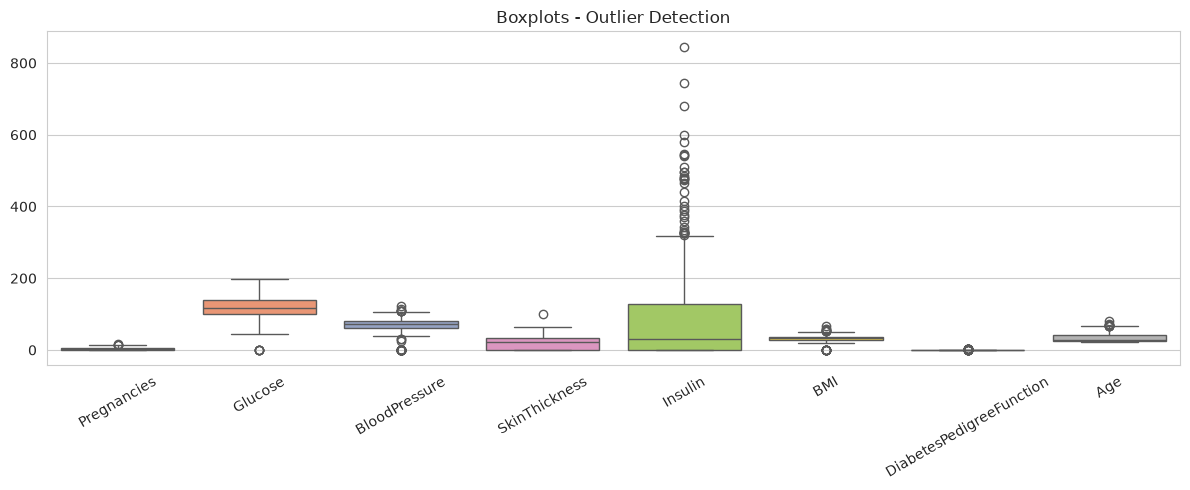

In [6]:
# Boxplots for outlier detection
plt.figure(figsize=(12,5))
sns.boxplot(data=df[COLS[:-1]], palette="Set2")
plt.title("Boxplots - Outlier Detection")
plt.xticks(rotation=30); plt.tight_layout()
plt.savefig("images/fig3_boxplots.png", dpi=130, bbox_inches="tight"); plt.show()

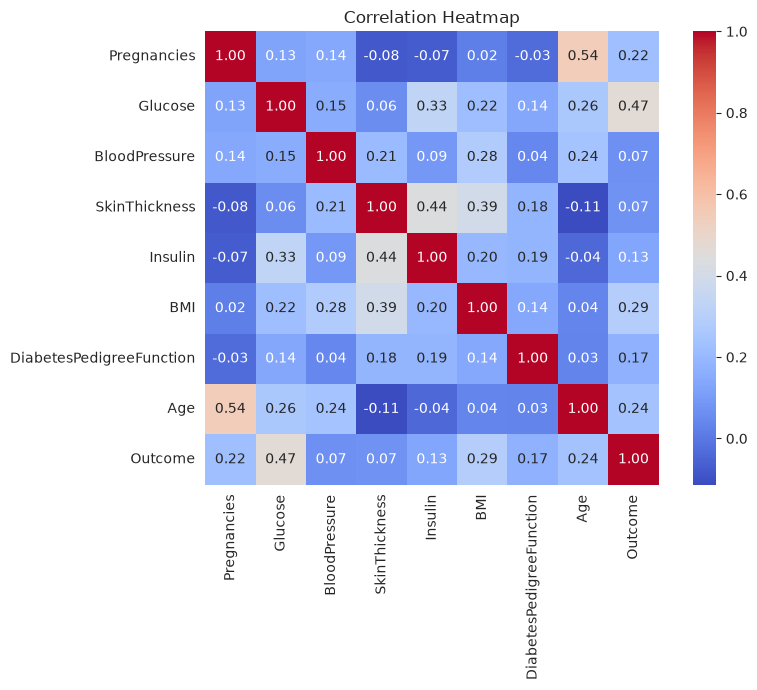

In [7]:
# Correlation heatmap
plt.figure(figsize=(9,7))
sns.heatmap(df.corr(), annot=True, fmt=".2f", cmap="coolwarm", square=True)
plt.title("Correlation Heatmap")
plt.tight_layout(); plt.savefig("images/fig4_correlation.png", dpi=130, bbox_inches="tight"); plt.show()

## Key Observations
- The dataset has 768 records and 9 columns (8 inputs + binary Outcome).
- Several medical attributes contain zero values which are biologically invalid and need treatment.
- Boxplots reveal potential outliers, especially in Insulin and DiabetesPedigreeFunction.
- Glucose, BMI and Age show the strongest positive correlation with the Outcome.